# Furnace_Tube_Data.csv 튜브 Furnace 시계열 데이터 분석 (원본)

0. 데이터 정제 (결측치 대체 · 이상치 확인 · 파생변수 생성)
1. 데이터 로드 및 기본 점검
2. 시간축 구조 (샘플링 주기, 공백, Run 구분)
3. Code_Num / Process_Type 구조
4. 센서 신호 특성 (자기상관 — 신호 vs 잡음)
5. 튜브 구역 온도 균일성
6. 제어 출력(OP / CP) 거동
7. 결측치 패턴
8. 시각화 & 결론

> 파생 컬럼(`이상치개수`, `정상여부`, `요일`)이 추가된 버전은 `Furnace_analysis.ipynb` 에서 다룹니다.

## 0. 데이터 정제 (요청 순서)

> **[역할]** 데이터 분석 전문가
> **[상황]** 데이터 분석을 위하여 정제 작업을 진행
> **[지시]** 아래 수행 순서대로 파이썬 코드 생성

1. `data` 폴더에서 `Furnace_Tube_Data.csv` 불러오기 (한글이 포함되어 있으면 `cp949` 사용)
2. 행과 열의 크기 확인
3. 변수별 평균값, 중앙값, 최빈값, 데이터 유형을 `| 변수명 | 평균값 | 중앙값 | 최빈값 | 데이터 유형 |` 형식으로 출력
4. 결측치 대체: 수치형 변수는 평균값, 범주형 변수는 최빈값
5. 이상치 확인: 그래프에서 한글과 음수값이 출력되도록 환경 설정 후 Box plot 으로 확인
6. 파생변수 생성 후 5개 행 출력
   - `이상치개수`: 각 변수에 1.5 × IQR 방식을 적용해 범위를 벗어난 개수의 합계
   - `정상여부`: 이상치개수가 3 이상이면 1, 3 미만이면 0
   - `요일`: `Datetime` 을 날짜 형식으로 변환한 뒤 요일을 영어로 생성

> 이 섹션은 정제본을 `data` 변수에 따로 만듭니다. 1장부터의 분석은 결측치를 그대로 둔 원본(`df`)을 사용합니다.

### 0-1. 데이터 불러오기

In [1]:
import re
import numpy as np
import pandas as pd

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', '{:,.4f}'.format)   # 지수 표기 대신 천 단위 콤마 + 소수점 4자리 (표시만, 데이터는 원본 유지)

PATH = '../data/Furnace_Tube_Data.csv'

# 인코딩 판단: UTF-8 로 읽히지 않으면(한글이 cp949 로 저장된 경우) cp949 사용
raw = open(PATH, 'rb').read()
try:
    text, encoding = raw.decode('utf-8'), 'utf-8'
except UnicodeDecodeError:
    text, encoding = raw.decode('cp949'), 'cp949'
has_korean = re.search('[가-힣]', text) is not None

data = pd.read_csv(PATH, encoding=encoding)
print(f'인코딩: {encoding} (한글 포함 여부: {has_korean})')
data.head()

인코딩: utf-8 (한글 포함 여부: False)


,Process_Type,Datetime,Code_Num,Z1_Temp,Z1_OP1,ST,Tube_Furnace1_OP,Tube_Furnace2_OP,Tube_Furnace3_OP,Tube_Furnace4_OP,Tube_Furnace_CP,Tube_Furnace1_Temp,Tube_Furnace2_Temp,Tube_Furnace3_Temp,Tube_Furnace4_Temp
0,OP-A,2022-01-03 11:22,GroupA,NaN,75.6648,NaN,73.5274,59.9894,52.2495,72.1349,0.4505,NaN,868.7595,NaN,NaN
1,OP-A,2022-01-03 11:22,GroupA,NaN,75.6706,NaN,79.1492,62.0272,50.6171,71.2452,0.4574,878.1169,883.8213,890.7408,894.4306
2,OP-A,2022-01-03 11:22,GroupA,99.6142,75.6776,68.7246,78.9463,62.2355,52.2183,72.7056,0.4549,866.4420,882.8500,864.3731,893.5305
3,OP-A,2022-01-03 11:22,GroupA,99.3762,75.8656,69.1611,78.4457,61.6083,52.8636,73.9756,0.4565,876.3505,906.2085,891.1079,896.3476
4,OP-C,2022-01-03 11:22,GroupA,99.8091,73.6468,69.1811,76.6738,61.5893,52.2972,71.8879,0.4601,903.5877,867.2151,893.2069,871.5943


### 0-2. 행과 열의 크기

In [2]:
print(f'행 {data.shape[0]:,}개 × 열 {data.shape[1]}개')

행 231,123개 × 열 15개


### 0-3. 변수별 평균값 · 중앙값 · 최빈값 · 데이터 유형

In [3]:
num_cols = data.select_dtypes('number').columns.tolist()
cat_cols = data.columns.drop(num_cols).tolist()

summary = pd.DataFrame({
    '변수명': data.columns,
    '평균값': [data[c].mean() if c in num_cols else np.nan for c in data.columns],
    '중앙값': [data[c].median() if c in num_cols else np.nan for c in data.columns],
    '최빈값': [data[c].mode().iloc[0] for c in data.columns],
    '데이터 유형': [str(data[c].dtype) for c in data.columns],
})

# 범주형 변수의 평균·중앙값은 '-' 로 표시
fmt_num = lambda v: f'{v:,.4f}' if isinstance(v, (float, np.floating)) else v
summary.style.hide(axis='index').format(fmt_num, na_rep='-')

변수명,평균값,중앙값,최빈값,데이터 유형
Process_Type,-,-,OP-C,str
Datetime,-,-,2022-01-03 11:23,str
Code_Num,-,-,GroupA,str
Z1_Temp,100.5097,100.5065,100.1106,float64
Z1_OP1,72.6226,72.9036,73.5491,float64
ST,69.0930,69.0847,67.5767,float64
Tube_Furnace1_OP,75.3096,78.7084,70.4392,float64
Tube_Furnace2_OP,47.5720,46.7344,44.9633,float64
Tube_Furnace3_OP,50.5330,50.6469,48.2645,float64
Tube_Furnace4_OP,70.2475,70.2691,68.0768,float64


### 0-4. 결측치 대체 (수치형 → 평균값, 범주형 → 최빈값)

In [4]:
na_before = data.isna().sum()

for c in num_cols:
    data[c] = data[c].fillna(data[c].mean())
for c in cat_cols:
    data[c] = data[c].fillna(data[c].mode().iloc[0])

na_after = data.isna().sum()
print(f'[결측치 대체 결과]')
for c in na_before[na_before > 0].index:
    rule = '평균값' if c in num_cols else '최빈값'
    print(f'  {c:<20s}: {na_before[c]:>4,}개 → {na_after[c]}개 ({rule} 대체)')
print(f'남은 결측치 합계: {na_after.sum():,}')

[결측치 대체 결과]
  Z1_Temp             :   25개 → 0개 (평균값 대체)
  ST                  :   25개 → 0개 (평균값 대체)
  Tube_Furnace1_OP    :  254개 → 0개 (평균값 대체)
  Tube_Furnace1_Temp  :    5개 → 0개 (평균값 대체)
  Tube_Furnace2_Temp  :   10개 → 0개 (평균값 대체)
  Tube_Furnace3_Temp  :    9개 → 0개 (평균값 대체)
  Tube_Furnace4_Temp  :   15개 → 0개 (평균값 대체)
남은 결측치 합계: 0


### 0-5. 이상치 확인 (Box plot)

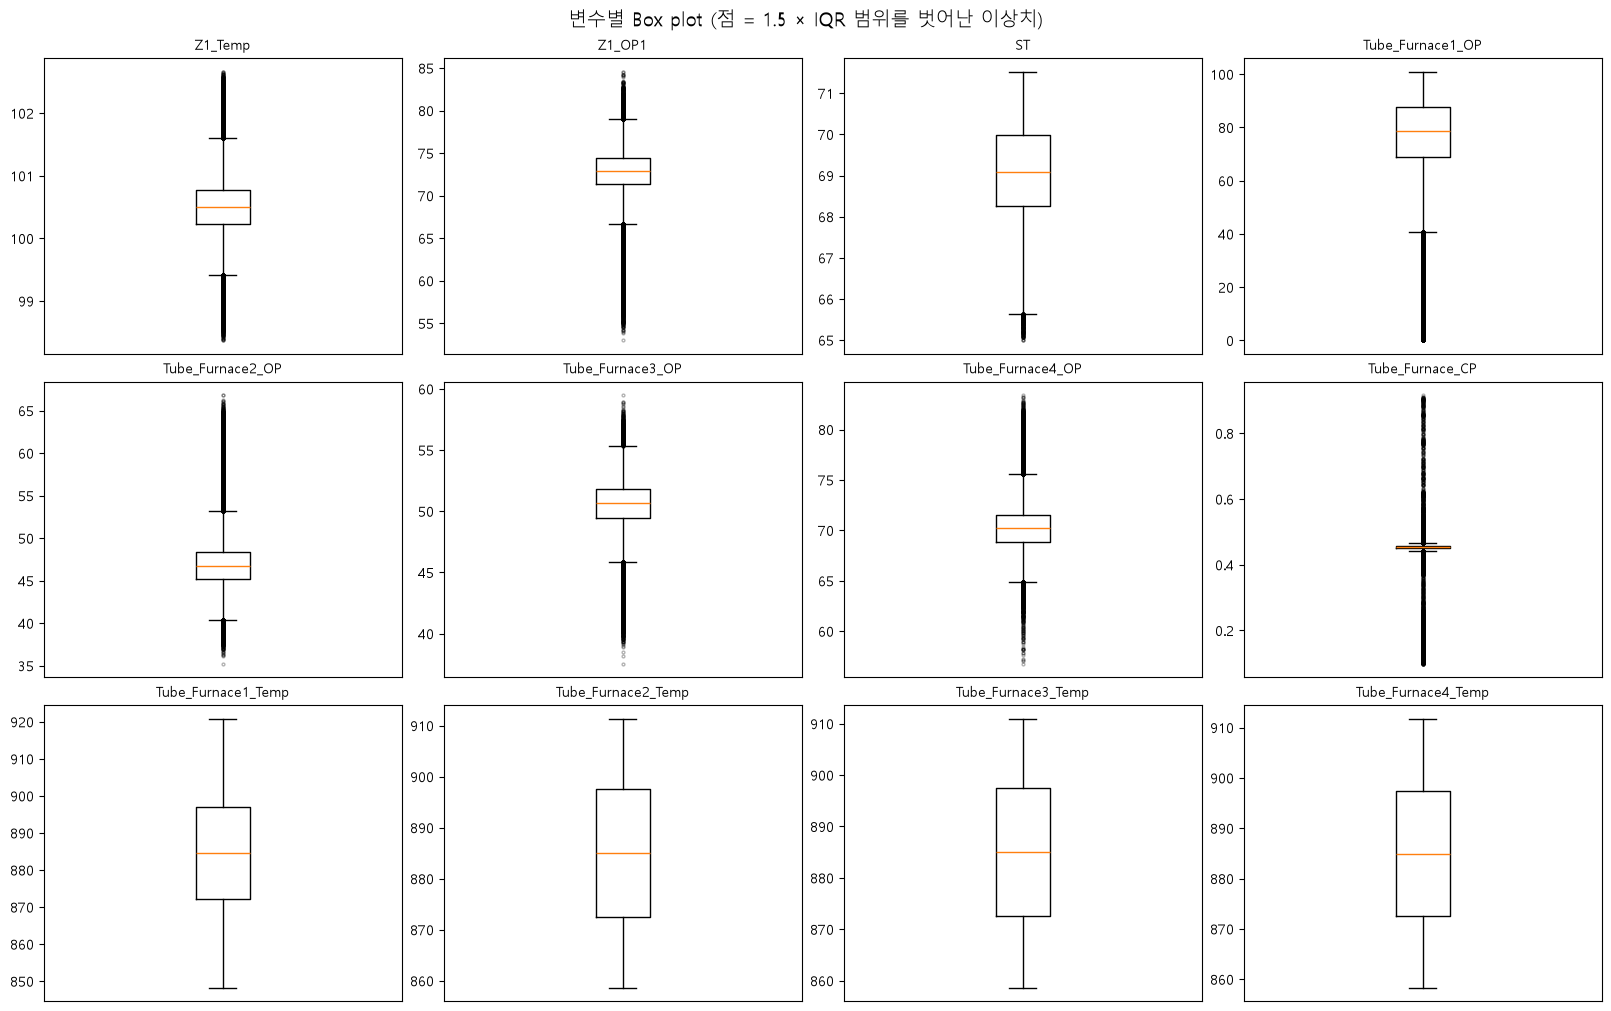

In [5]:
import matplotlib.pyplot as plt
%matplotlib inline

# 한글 폰트 + 음수 부호(-) 깨짐 방지
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 변수마다 단위가 달라 변수별로 따로 그림
fig, axes = plt.subplots(3, 4, figsize=(16, 10), constrained_layout=True)
for ax, c in zip(axes.ravel(), num_cols):
    ax.boxplot(data[c], flierprops=dict(marker='o', markersize=2, alpha=0.3))
    ax.set_title(c, fontsize=10)
    ax.set_xticks([])
    ax.ticklabel_format(axis='y', style='plain', useOffset=False)
fig.suptitle('변수별 Box plot (점 = 1.5 × IQR 범위를 벗어난 이상치)', fontsize=14)
plt.show()

In [6]:
q1, q3 = data[num_cols].quantile(0.25), data[num_cols].quantile(0.75)
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
is_outlier = (data[num_cols] < lower) | (data[num_cols] > upper)

outlier_tbl = pd.DataFrame({'하한': lower, '상한': upper, '이상치 수': is_outlier.sum(),
                            '이상치 비율(%)': is_outlier.mean() * 100})
outlier_tbl.sort_values('이상치 수', ascending=False)

,하한,상한,이상치 수,이상치 비율(%)
Tube_Furnace2_OP,40.4286,53.2034,23510,10.1721
Tube_Furnace1_OP,40.7230,115.8564,14607,6.3200
Tube_Furnace_CP,0.4431,0.4666,12791,5.5343
Z1_OP1,66.6901,79.0339,9750,4.2185
Tube_Furnace4_OP,64.8574,75.5726,6640,2.8729
Z1_Temp,99.4160,101.5975,6020,2.6047
Tube_Furnace3_OP,45.8507,55.3681,5602,2.4238
ST,65.6390,72.6103,318,0.1376
Tube_Furnace1_Temp,834.7033,934.3150,0,0.0000
Tube_Furnace2_Temp,835.0988,935.0006,0,0.0000


### 0-6. 파생변수 생성 (이상치개수 · 정상여부 · 요일)

In [7]:
data['이상치개수'] = is_outlier.sum(axis=1)
data['정상여부'] = (data['이상치개수'] >= 3).astype(int)
data['요일'] = pd.to_datetime(data['Datetime']).dt.day_name()

data[['Datetime', *num_cols, '이상치개수', '정상여부', '요일']].head()

,Datetime,Z1_Temp,Z1_OP1,ST,Tube_Furnace1_OP,Tube_Furnace2_OP,Tube_Furnace3_OP,Tube_Furnace4_OP,Tube_Furnace_CP,Tube_Furnace1_Temp,Tube_Furnace2_Temp,Tube_Furnace3_Temp,Tube_Furnace4_Temp,이상치개수,정상여부,요일
0,2022-01-03 11:22,100.5097,75.6648,69.0930,73.5274,59.9894,52.2495,72.1349,0.4505,884.5382,868.7595,885.0257,884.9877,1,0,Monday
1,2022-01-03 11:22,100.5097,75.6706,69.0930,79.1492,62.0272,50.6171,71.2452,0.4574,878.1169,883.8213,890.7408,894.4306,1,0,Monday
2,2022-01-03 11:22,99.6142,75.6776,68.7246,78.9463,62.2355,52.2183,72.7056,0.4549,866.4420,882.8500,864.3731,893.5305,1,0,Monday
3,2022-01-03 11:22,99.3762,75.8656,69.1611,78.4457,61.6083,52.8636,73.9756,0.4565,876.3505,906.2085,891.1079,896.3476,2,0,Monday
4,2022-01-03 11:22,99.8091,73.6468,69.1811,76.6738,61.5893,52.2972,71.8879,0.4601,903.5877,867.2151,893.2069,871.5943,1,0,Monday


In [8]:
# 참고: 이미 만들어진 Furnace_analysis.csv 의 파생 컬럼과 비교
ref = pd.read_csv('../data/Furnace_analysis.csv')
for c in ['이상치개수', '정상여부', '요일']:
    print(f'{c:<6s} 일치율: {(data[c].values == ref[c].values).mean():.2%}')
print(f'정상여부 = 1 비율: {data["정상여부"].mean():.2%} ({data["정상여부"].sum():,}행)')

이상치개수  일치율: 100.00%
정상여부   일치율: 100.00%
요일     일치율: 100.00%
정상여부 = 1 비율: 1.70% (3,940행)


## 1. 데이터 로드 및 기본 점검

In [9]:
import warnings
import numpy as np
import pandas as pd

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', '{:,.4f}'.format)   # 지수 표기 대신 천 단위 콤마 + 소수점 4자리 (표시만, 데이터는 원본 유지)

df = pd.read_csv('../data/Furnace_Tube_Data.csv')
df['dt'] = pd.to_datetime(df['Datetime'])

NUM = ['Z1_Temp', 'Z1_OP1', 'ST',
       'Tube_Furnace1_OP', 'Tube_Furnace2_OP', 'Tube_Furnace3_OP', 'Tube_Furnace4_OP', 'Tube_Furnace_CP',
       'Tube_Furnace1_Temp', 'Tube_Furnace2_Temp', 'Tube_Furnace3_Temp', 'Tube_Furnace4_Temp']
TEMPS = [f'Tube_Furnace{i}_Temp' for i in range(1, 5)]
OPS = [f'Tube_Furnace{i}_OP' for i in range(1, 5)]

print(f'데이터 크기: {df.shape[0]:,}행 × {df.shape[1] - 1}열 (dt 파싱 컬럼 제외)')
df.head()

데이터 크기: 231,123행 × 15열 (dt 파싱 컬럼 제외)


,Process_Type,Datetime,Code_Num,Z1_Temp,Z1_OP1,ST,Tube_Furnace1_OP,Tube_Furnace2_OP,Tube_Furnace3_OP,Tube_Furnace4_OP,Tube_Furnace_CP,Tube_Furnace1_Temp,Tube_Furnace2_Temp,Tube_Furnace3_Temp,Tube_Furnace4_Temp,dt
0,OP-A,2022-01-03 11:22,GroupA,NaN,75.6648,NaN,73.5274,59.9894,52.2495,72.1349,0.4505,NaN,868.7595,NaN,NaN,2022-01-03 11:22:00
1,OP-A,2022-01-03 11:22,GroupA,NaN,75.6706,NaN,79.1492,62.0272,50.6171,71.2452,0.4574,878.1169,883.8213,890.7408,894.4306,2022-01-03 11:22:00
2,OP-A,2022-01-03 11:22,GroupA,99.6142,75.6776,68.7246,78.9463,62.2355,52.2183,72.7056,0.4549,866.4420,882.8500,864.3731,893.5305,2022-01-03 11:22:00
3,OP-A,2022-01-03 11:22,GroupA,99.3762,75.8656,69.1611,78.4457,61.6083,52.8636,73.9756,0.4565,876.3505,906.2085,891.1079,896.3476,2022-01-03 11:22:00
4,OP-C,2022-01-03 11:22,GroupA,99.8091,73.6468,69.1811,76.6738,61.5893,52.2972,71.8879,0.4601,903.5877,867.2151,893.2069,871.5943,2022-01-03 11:22:00


In [10]:
na = df[NUM].isna().sum()
print(f'결측치 합계: {na.sum():,}셀 / 결측 포함 행: {df[NUM].isna().any(axis=1).sum():,}행')
print(f'중복 행    : {df.drop(columns="dt").duplicated().sum():,}')
print()
print(f'[컬럼별 결측치]')
for c, v in na[na > 0].items():
    print(f'  {c:<20s}: {v:>4,}개 ({v / len(df):.3%})')

결측치 합계: 343셀 / 결측 포함 행: 284행


중복 행    : 0

[컬럼별 결측치]
  Z1_Temp             :   25개 (0.011%)
  ST                  :   25개 (0.011%)
  Tube_Furnace1_OP    :  254개 (0.110%)
  Tube_Furnace1_Temp  :    5개 (0.002%)
  Tube_Furnace2_Temp  :   10개 (0.004%)
  Tube_Furnace3_Temp  :    9개 (0.004%)
  Tube_Furnace4_Temp  :   15개 (0.006%)


In [11]:
desc = df[NUM].describe().T
desc['count'] = desc['count'].astype(int)
desc['nunique'] = df[NUM].nunique()
desc['cv%'] = desc['std'] / desc['mean'] * 100

display(desc)

,count,mean,std,min,25%,50%,75%,max,nunique,cv%
Z1_Temp,231098,100.5097,0.4272,98.3709,100.2340,100.5065,100.7794,102.6640,229233,0.4250
Z1_OP1,231123,72.6226,3.0091,52.9816,71.3191,72.9036,74.4050,84.5911,93274,4.1435
ST,231098,69.0930,1.0783,64.9914,68.2532,69.0847,69.9961,71.5270,231023,1.5606
Tube_Furnace1_OP,230869,75.3096,20.6631,0.0054,68.8801,78.7084,87.6979,101.0000,230834,27.4375
Tube_Furnace2_OP,231123,47.5720,4.4135,35.2017,45.2192,46.7344,48.4129,66.8253,231090,9.2775
Tube_Furnace3_OP,231123,50.5330,1.9651,37.5194,49.4197,50.6469,51.7991,59.4909,231098,3.8888
Tube_Furnace4_OP,231123,70.2475,2.2818,56.7485,68.8756,70.2691,71.5544,83.4108,231071,3.2482
Tube_Furnace_CP,231123,0.4497,0.0442,0.0980,0.4520,0.4549,0.4578,0.9163,229402,9.8246
Tube_Furnace1_Temp,231118,884.5382,14.6056,848.2845,872.0574,884.5274,896.9609,920.8327,231055,1.6512
Tube_Furnace2_Temp,231113,885.0415,14.4184,858.6697,872.5614,885.0474,897.5376,911.3588,231063,1.6291


## 2. 시간축 구조

In [12]:
ts = df['dt']
per_min = df.groupby('dt').size()
gaps = ts.drop_duplicates().diff().dropna()

print(f'기간         : {ts.min()} ~ {ts.max()}')
print(f'정렬 여부    : {ts.is_monotonic_increasing}')
print(f'고유 시각(분): {ts.nunique():,}개')
print(f'분당 행 수   : 평균 {per_min.mean():,.4f} / 중앙값 {per_min.median():.0f} / 최대 {per_min.max()}')
print(f'→ 타임스탬프는 분 단위로 잘려 있고, 실제 샘플링은 약 1초 간격(분당 ~58행)으로 추정')
print()
print(f'연속 분 간격(1분): {(gaps == pd.Timedelta("1min")).sum():,}회 / 1시간 초과 공백: {(gaps > pd.Timedelta("1h")).sum()}회')

기간         : 2022-01-03 11:22:00 ~ 2022-01-15 19:49:00
정렬 여부    : True
고유 시각(분): 3,996개
분당 행 수   : 평균 57.8386 / 중앙값 59 / 최대 60
→ 타임스탬프는 분 단위로 잘려 있고, 실제 샘플링은 약 1초 간격(분당 ~58행)으로 추정

연속 분 간격(1분): 3,985회 / 1시간 초과 공백: 10회


In [13]:
# Code_Num 이 바뀌는 지점 = Run(가동 구간) 경계 (공백과 정확히 일치)
df['run'] = (df['Code_Num'] != df['Code_Num'].shift()).cumsum()
runs = df.groupby('run').agg(Code_Num=('Code_Num', 'first'), start=('dt', 'min'), end=('dt', 'max'), rows=('dt', 'size'))
runs['minutes'] = ((runs['end'] - runs['start']).dt.total_seconds() / 60 + 1).astype(int)
runs['gap_before'] = (runs['start'] - runs['end'].shift()).astype(str).str.replace('0 days ', '')
print(f'Run 수: {len(runs)}개 (Code_Num 7종, GroupA~D 는 2회씩 반복)')
runs

Run 수: 11개 (Code_Num 7종, GroupA~D 는 2회씩 반복)


,Code_Num,start,end,rows,minutes,gap_before
run,,,,,,
1,GroupA,2022-01-03 11:22:00,2022-01-03 13:27:00,7342,126,NaN
2,GroupB,2022-01-03 22:35:00,2022-01-04 02:20:00,13299,226,09:08:00
3,GroupC,2022-01-04 22:34:00,2022-01-05 06:20:00,26982,467,20:14:00
4,GroupD,2022-01-05 14:32:00,2022-01-05 23:40:00,31729,549,08:12:00
5,GroupE,2022-01-06 22:29:00,2022-01-07 00:16:00,6218,108,22:49:00
6,GroupF,2022-01-07 04:07:00,2022-01-07 11:31:00,25708,445,03:51:00
7,GroupG,2022-01-08 04:43:00,2022-01-08 08:20:00,12559,218,17:12:00
8,GroupA,2022-01-10 11:17:00,2022-01-11 00:50:00,46836,814,2 days 02:57:00
9,GroupB,2022-01-12 13:09:00,2022-01-12 23:21:00,35348,613,1 days 12:19:00


## 3. Code_Num / Process_Type 구조

In [14]:
switches = (df['Process_Type'] != df['Process_Type'].shift()).sum()
print(f'Process_Type 분포: ' + ', '.join(f'{k} {v:,}행 ({v / len(df):.1%})' for k, v in df['Process_Type'].value_counts().items()))
print(f'Process_Type 전환 횟수: {switches:,}회 → 배치 단위가 아니라 행 단위로 섞여 있음')
print()
print(f'[Code_Num × Process_Type 행 수]')
print(pd.crosstab(df['Code_Num'], df['Process_Type'], margins=True))

Process_Type 분포: OP-C 182,486행 (79.0%), OP-B 48,093행 (20.8%), OP-A 544행 (0.2%)
Process_Type 전환 횟수: 23,360회 → 배치 단위가 아니라 행 단위로 섞여 있음

[Code_Num × Process_Type 행 수]
Process_Type  OP-A   OP-B    OP-C     All
Code_Num                                 
GroupA         512  16843   36823   54178
GroupB           0  14150   34497   48647
GroupC           5   7724   23587   31316
GroupD           4   5108   47385   52497
GroupE           0   1043    5175    6218
GroupF          23   1951   23734   25708
GroupG           0   1274   11285   12559
All            544  48093  182486  231123


In [15]:
print(f'[Process_Type 별 센서 평균]')
print(df.groupby('Process_Type')[NUM].mean().T)

[Process_Type 별 센서 평균]
Process_Type           OP-A     OP-B     OP-C
Z1_Temp             99.8646 100.6699 100.4694
Z1_OP1              75.1890  70.5385  73.1642
ST                  69.3428  69.2118  69.0609
Tube_Furnace1_OP    80.1214  74.8763  75.4096
Tube_Furnace2_OP    58.6588  49.8167  46.9474
Tube_Furnace3_OP    50.9638  50.4353  50.5574
Tube_Furnace4_OP    71.4246  70.0811  70.2879
Tube_Furnace_CP      0.4550   0.4485   0.4500
Tube_Furnace1_Temp 884.4333 884.5448 884.5367
Tube_Furnace2_Temp 883.6285 885.0111 885.0538
Tube_Furnace3_Temp 884.0779 885.0050 885.0339
Tube_Furnace4_Temp 885.7053 885.0476 884.9698


## 4. 센서 신호 특성 — 자기상관으로 신호/잡음 구분

In [16]:
minute_mean = df.groupby('dt')[NUM].mean()
ac = pd.DataFrame({
    'lag1_row': [df[c].autocorr(1) for c in NUM],
    'lag1_minute_mean': [minute_mean[c].autocorr(1) for c in NUM],
    'std': [df[c].std() for c in NUM],
}, index=NUM)
print(f'[lag-1 자기상관: 행 단위 / 분 평균 단위]')
print(ac)
print()
print(f'→ OP·CP·ST 는 행 단위 자기상관 0.54~1.00 (연속적인 제어 신호)')
print(f'→ 튜브 온도 4개는 행 단위 자기상관 ≈ 0 (±14℃ 수준의 독립 잡음처럼 보임)')

[lag-1 자기상관: 행 단위 / 분 평균 단위]
                    lag1_row  lag1_minute_mean     std
Z1_Temp               0.5420            0.9313  0.4272
Z1_OP1                0.8279            0.9524  3.0091
ST                    0.9194            0.9969  1.0783
Tube_Furnace1_OP      0.9878            0.7792 20.6631
Tube_Furnace2_OP      0.9673            0.9873  4.4135
Tube_Furnace3_OP      0.8401            0.9511  1.9651
Tube_Furnace4_OP      0.8833            0.9084  2.2818
Tube_Furnace_CP       0.9956            0.9723  0.0442
Tube_Furnace1_Temp    0.0230            0.5249 14.6056
Tube_Furnace2_Temp    0.0021            0.0204 14.4184
Tube_Furnace3_Temp    0.0040           -0.0030 14.4392
Tube_Furnace4_Temp    0.0004            0.0382 14.4313

→ OP·CP·ST 는 행 단위 자기상관 0.54~1.00 (연속적인 제어 신호)
→ 튜브 온도 4개는 행 단위 자기상관 ≈ 0 (±14℃ 수준의 독립 잡음처럼 보임)


In [17]:
print(f'[센서 간 상관 (Pearson)]')
print(df[NUM].corr())

[센서 간 상관 (Pearson)]


                    Z1_Temp  Z1_OP1      ST  Tube_Furnace1_OP  Tube_Furnace2_OP  Tube_Furnace3_OP  Tube_Furnace4_OP  Tube_Furnace_CP  Tube_Furnace1_Temp  Tube_Furnace2_Temp  Tube_Furnace3_Temp  \
Z1_Temp              1.0000 -0.5360  0.1442           -0.0086           -0.0239           -0.0424           -0.0531          -0.0450              0.0025              0.0000              0.0009   
Z1_OP1              -0.5360  1.0000 -0.1542            0.0224           -0.0062            0.1156            0.1846           0.0609             -0.0003              0.0025              0.0011   
ST                   0.1442 -0.1542  1.0000           -0.0606            0.2042           -0.1637           -0.3069          -0.1298              0.0058             -0.0029             -0.0005   
Tube_Furnace1_OP    -0.0086  0.0224 -0.0606            1.0000            0.0374            0.1143            0.0812           0.1546             -0.1201             -0.0012              0.0005   
Tube_Furnace2_OP    

## 5. 튜브 구역 온도 균일성

In [18]:
row_range = df[TEMPS].max(axis=1) - df[TEMPS].min(axis=1)
min_range = minute_mean[TEMPS].max(axis=1) - minute_mean[TEMPS].min(axis=1)
print(f'구역 평균 온도: ' + ', '.join(f'{c.replace("Tube_Furnace", "Z").replace("_Temp", "")} {df[c].mean():,.4f}℃' for c in TEMPS))
print(f'행 단위 구역 간 편차(max-min): 평균 {row_range.mean():,.4f}℃ / 중앙값 {row_range.median():,.4f}℃ / 최대 {row_range.max():,.4f}℃')
print(f'분 평균 구역 간 편차(max-min): 평균 {min_range.mean():,.4f}℃ / 중앙값 {min_range.median():,.4f}℃ / 최대 {min_range.max():,.4f}℃')
print()
print(f'[Run 별 구역 평균 온도]')
print(df.groupby('run')[TEMPS].mean())

구역 평균 온도: Z1 884.5382℃, Z2 885.0415℃, Z3 885.0257℃, Z4 884.9877℃
행 단위 구역 간 편차(max-min): 평균 30.0918℃ / 중앙값 30.7722℃ / 최대 60.5483℃
분 평균 구역 간 편차(max-min): 평균 4.5142℃ / 중앙값 4.1524℃ / 최대 33.2208℃

[Run 별 구역 평균 온도]
     Tube_Furnace1_Temp  Tube_Furnace2_Temp  Tube_Furnace3_Temp  Tube_Furnace4_Temp
run                                                                                
1              884.3056            885.1232            885.1369            885.1257
2              884.2767            885.0244            884.9834            884.9956
3              884.6320            884.9560            884.9597            884.9411
4              884.7843            884.9491            885.0496            884.8993
5              884.4693            884.9714            885.0584            885.0877
6              884.4255            885.0308            885.0579            884.9554
7              885.4764            885.0897            885.0724            885.1838
8              884.2836            

## 6. 제어 출력(OP / CP) 거동

In [19]:
print(f'[Run 별 제어 출력 평균]')
print(df.groupby('run')[['Z1_Temp', 'Z1_OP1', 'ST'] + OPS + ['Tube_Furnace_CP']].mean())

[Run 별 제어 출력 평균]
     Z1_Temp  Z1_OP1      ST  Tube_Furnace1_OP  Tube_Furnace2_OP  Tube_Furnace3_OP  Tube_Furnace4_OP  Tube_Furnace_CP
run                                                                                                                  
1   100.5016 72.2527 69.9530           76.2084           59.8395           51.1798           70.7502           0.4555
2   100.5281 72.2356 69.9618           75.3876           59.6716           52.5151           71.1419           0.4551
3   100.5113 70.7202 69.9240           71.1982           46.3498           48.7650           67.6304           0.4543
4   100.5051 72.4242 69.9255           77.8257           46.5303           51.0689           69.9420           0.4548
5   100.5099 72.7746 69.8226           75.2701           45.6629           50.7557           70.2709           0.4550
6   100.5094 72.8727 69.7803           75.1246           45.9751           50.4684           69.4021           0.4545
7   100.5563 73.3289 70.1240           

In [20]:
# Tube_Furnace1_OP 는 0 근처까지 떨어지는 구간이 반복됨
op1 = df['Tube_Furnace1_OP']
q = op1.quantile([0, .01, .05, .10, .50, .90, 1])
print(f'Tube_Furnace1_OP 분위수: ' + ', '.join(f'{k:.0%}={v:,.4f}' for k, v in q.items()))
low = op1 < 40
print(f'OP1 < 40 비율: {low.mean():.2%} ({low.sum():,}행)')
print(f'OP1 < 40 일 때 Tube1 온도 평균 {df.loc[low, "Tube_Furnace1_Temp"].mean():,.4f}℃ vs 그 외 {df.loc[~low, "Tube_Furnace1_Temp"].mean():,.4f}℃')

Tube_Furnace1_OP 분위수: 0%=0.0054, 1%=1.2553, 5%=31.0252, 10%=51.7294, 50%=78.7084, 90%=99.8594, 100%=101.0000
OP1 < 40 비율: 6.19% (14,307행)
OP1 < 40 일 때 Tube1 온도 평균 889.6062℃ vs 그 외 884.2038℃


In [21]:
# GroupG Run(2022-01-08) 후반 CP 급락
cp_g = df[df['run'] == 7].groupby('dt')['Tube_Furnace_CP'].mean()
print(f'전체 CP 중앙값: {df["Tube_Furnace_CP"].median():,.4f}')
print(f'GroupG Run CP (15분 간격 분 평균)')
for t, v in cp_g.iloc[::15].items():
    print(f'  {t:%m-%d %H:%M}  {v:,.4f}')

전체 CP 중앙값: 0.4549
GroupG Run CP (15분 간격 분 평균)
  01-08 04:43  0.4553
  01-08 04:58  0.4535
  01-08 05:13  0.4564
  01-08 05:28  0.4531
  01-08 05:43  0.4538
  01-08 05:58  0.4553
  01-08 06:13  0.4561
  01-08 06:28  0.4548
  01-08 06:43  0.4545
  01-08 06:58  0.4059
  01-08 07:13  0.2043
  01-08 07:28  0.1709
  01-08 07:43  0.1272
  01-08 07:58  0.1231
  01-08 08:13  0.1100


## 7. 결측치 패턴

In [22]:
na_rows = df[df[NUM].isna().any(axis=1)]
print(f'[Run 별 결측 포함 행 수]')
print(na_rows.groupby('run').size().rename('na_rows').to_frame().T)
op1_na_idx = df.index[df['Tube_Furnace1_OP'].isna()].to_series()
print()
print(f'Tube_Furnace1_OP 결측 {len(op1_na_idx)}개 중 연속 구간: run 2 에 {(na_rows["run"] == 2).sum()}행, run 10 에 {(na_rows["run"] == 10).sum()}행 (블록 형태)')
print(f'나머지 컬럼 결측은 Run 시작 직후 등에 산발적으로 1~수 개')

[Run 별 결측 포함 행 수]
run      1    2   3   4   5   6   7   8   9   10  11
na_rows   2  179   8   2   2   3   2   3   4  75   4

Tube_Furnace1_OP 결측 254개 중 연속 구간: run 2 에 179행, run 10 에 75행 (블록 형태)
나머지 컬럼 결측은 Run 시작 직후 등에 산발적으로 1~수 개


## 8. 시각화

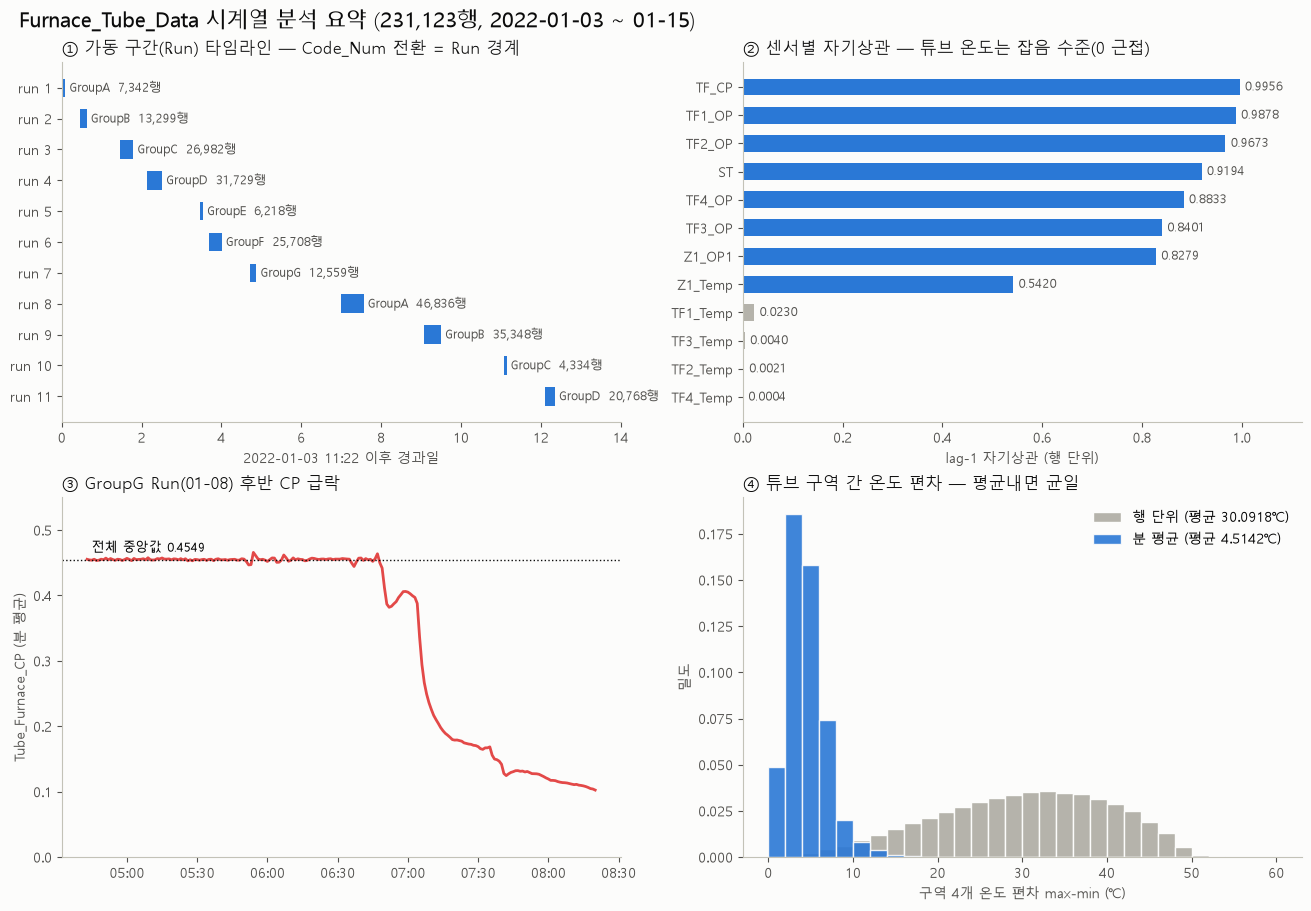

In [23]:
import os
import matplotlib.pyplot as plt
%matplotlib inline

plt.rcParams.update({'font.family': 'Malgun Gothic', 'axes.unicode_minus': False, 'font.size': 10,
                     'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': '#52514e', 'xtick.color': '#52514e',
                     'ytick.color': '#52514e', 'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
                     'axes.formatter.useoffset': False, 'axes.formatter.limits': (-99, 99)})   # 축 지수 표기 끄기
BLUE, ORANGE, RED, GRAY, INK = '#2a78d6', '#eb6834', '#e34948', '#b5b3ab', '#0b0b0b'

fig, ax = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)
fig.suptitle('Furnace_Tube_Data 시계열 분석 요약 (231,123행, 2022-01-03 ~ 01-15)', fontsize=15, color=INK, x=0.01, ha='left')

# ① Run 타임라인
a = ax[0, 0]
for i, (r, row) in enumerate(runs.iterrows()):
    a.barh(i, (row['end'] - row['start']).total_seconds() / 86400 + 1 / 1440,
           left=(row['start'] - runs['start'].min()).total_seconds() / 86400, color=BLUE, height=0.6)
    a.text((row['end'] - runs['start'].min()).total_seconds() / 86400 + 0.1, i,
           f"{row['Code_Num']}  {row['rows']:,}행", va='center', fontsize=8.5, color='#52514e')
a.set_yticks(range(len(runs)), [f'run {r}' for r in runs.index]); a.invert_yaxis()
a.set_xlim(0, 14); a.set_xlabel('2022-01-03 11:22 이후 경과일')
a.set_title('① 가동 구간(Run) 타임라인 — Code_Num 전환 = Run 경계', loc='left', color=INK)

# ② 자기상관
a = ax[0, 1]; s = ac['lag1_row'].sort_values()
a.barh([n.replace('Tube_Furnace', 'TF') for n in s.index], s.values, height=0.6,
       color=[GRAY if v < 0.1 else BLUE for v in s.values])
for i, v in enumerate(s.values):
    a.text(max(v, 0) + 0.01, i, f'{v:,.4f}', va='center', fontsize=8.5, color='#52514e')
a.set_xlim(0, 1.12); a.set_xlabel('lag-1 자기상관 (행 단위)')
a.set_title('② 센서별 자기상관 — 튜브 온도는 잡음 수준(0 근접)', loc='left', color=INK)

# ③ GroupG CP 급락
a = ax[1, 0]
a.plot(cp_g.index, cp_g.values, color=RED, lw=2)
a.axhline(df['Tube_Furnace_CP'].median(), color=INK, lw=1, ls=':')
a.text(cp_g.index[2], df['Tube_Furnace_CP'].median() + 0.012, f'전체 중앙값 {df["Tube_Furnace_CP"].median():,.4f}', fontsize=9)
a.set_ylabel('Tube_Furnace_CP (분 평균)'); a.set_ylim(0, 0.55)
a.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%H:%M'))
a.set_title('③ GroupG Run(01-08) 후반 CP 급락', loc='left', color=INK)

# ④ 구역 간 온도 편차
a = ax[1, 1]; bins = np.arange(0, 62, 2)
a.hist(row_range, bins=bins, color=GRAY, edgecolor='#fcfcfb', density=True, label=f'행 단위 (평균 {row_range.mean():,.4f}℃)')
a.hist(min_range, bins=bins, color=BLUE, edgecolor='#fcfcfb', density=True, alpha=0.9, label=f'분 평균 (평균 {min_range.mean():,.4f}℃)')
a.set_xlabel('구역 4개 온도 편차 max-min (℃)'); a.set_ylabel('밀도'); a.legend(frameon=False)
a.set_title('④ 튜브 구역 간 온도 편차 — 평균내면 균일', loc='left', color=INK)

os.makedirs('output', exist_ok=True)
fig.savefig('output/Furnace_Tube_Data_summary.png', dpi=150)
plt.show()

## 결론 요약
- **구조**: 231,123행 × 15열, 2022-01-03 11:22 ~ 01-15 19:49. 타임스탬프는 분 단위이며 분당 ~58행(약 1초 샘플링)
- **Run**: `Code_Num` 전환 지점 = 3.8시간~2일 공백 = 가동 구간 경계 → **11개 Run** (GroupA~D 는 2회, E~G 1회)
- **Process_Type**(OP-A/B/C)은 행 단위로 23,360회 전환 → 배치 구분이 아니라 행 속성
- **신호 특성**: OP·CP·ST·Z1 은 연속 제어 신호(자기상관 0.54~1.00), **튜브 온도 4개는 자기상관 ≈ 0** (885℃ ± 14℃ 잡음 형태)
- **균일성**: 행 단위 구역 편차 평균 30.1℃지만 분 평균 시 4.5℃ → 순간값보다 평균 기반 모니터링 권장
- **이벤트**: GroupG Run(01-08) 07시 이후 **CP 0.45 → 0.11 급락**, Tube_Furnace1_OP 는 약 6% 시간 동안 40 미만(0 근처)으로 떨어짐
- **결측**: 343셀(284행) — Tube_Furnace1_OP 254개가 run 2·10 에 블록으로 몰려 있음